# Linear SVM Hyperparameter Tuning

This experiment uses the same Hugging Face TweetEval emotion dataset, official train/validation/test splits, and tweet preprocessing as TED-NLP.ipynb. It compares baseline and tuned Linear SVM models using both TF-IDF and bag-of-words (BoW). Training data is used for stratified cross-validation; validation selects the final settings, and the test split is reserved for the final report.

The selected preprocessing follows TED-NLP: WordNet lemmatization with stopwords removed while keeping negation and contrast words.

## 1. Load the dataset

In [22]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import emoji
import nltk

dataset = load_dataset("cardiffnlp/tweet_eval", "emotion")

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

emotion_labels = {0: "anger", 1: "joy", 2: "optimism", 3: "sadness"}
label_names = list(emotion_labels.values())
for frame in (train_df, val_df, test_df):
    frame["emotion"] = frame["label"].map(emotion_labels)

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
display(train_df[["text", "label","emotion"]].head())


Train: 3,257 | Validation: 374 | Test: 1,421


,text,label,emotion
0,“Worry is a down payment on a problem you may ...,2,optimism
1,My roommate: it's okay that we can't spell bec...,0,anger
2,No but that's so cute. Atsu was probably shy a...,1,joy
3,Rooneys fucking untouchable isn't he? Been fuc...,0,anger
4,it's pretty depressing when u hit pan on ur fa...,3,sadness


## 2. Remove exact duplicate training tweets

In [23]:
duplicate_label_counts = train_df.groupby("text")["label"].nunique()
if duplicate_label_counts.gt(1).any():
    raise ValueError("Repeated training tweets have conflicting labels; review them before deduplication.")

train_rows_before = len(train_df)
train_df = train_df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
print(f"Removed {train_rows_before - len(train_df)} duplicate training tweets; train rows now: {len(train_df):,}.")


Removed 25 duplicate training tweets; train rows now: 3,232.


## 3. Prepare NLTK resources and use TED-NLP preprocessing

In [24]:
for resource in ("wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"):
    nltk.download(resource, quiet=True)


In [25]:
import html
import re
import unicodedata
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

lemmatizer = WordNetLemmatizer()
tweet_tokenizer = TweetTokenizer(preserve_case=False)
keep_words = {
    "no", "nor", "not", "never", "very", "too", "so", "more", "most", "less",
    "but", "however", "yet", "up", "down",
}
stop_words = set(ENGLISH_STOP_WORDS) - keep_words

contractions = {
    "can't": "can not",
    "won't": "will not",
    "shan't": "shall not",
    "ain't": "not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "hasn't": "has not",
    "haven't": "have not",
    "hadn't": "had not",
    "couldn't": "could not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "mustn't": "must not",
    "needn't": "need not",
    "mightn't": "might not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "i've": "i have",
    "you've": "you have",
    "we've": "we have",
    "they've": "they have",
    "i'll": "i will",
    "you'll": "you will",
    "he'll": "he will",
    "she'll": "she will",
    "it'll": "it will",
    "we'll": "we will",
    "they'll": "they will",
    "let's": "let us",
}
contraction_pattern = re.compile(
    r"\b(?:" + "|".join(
        re.escape(item) for item in sorted(contractions, key=len, reverse=True)
    ) + r")\b",
    flags=re.IGNORECASE,
)

# Convert common ASCII emoticons before removing punctuation.
emoticon_variants = {
    "emoticon_broken_heart": ["</3"],
    "emoticon_heart": ["<3"],
    "emoticon_wink": [";)", ";-)", ";]", ";-]"],
    "emoticon_playful": [":p", ":-p", ";p", ";-p"],
    "emoticon_positive": [":)", ":-)", ":]", ":-]", ":d", ":-d", "=)", "=-)", "(:", "(-:"],
    "emoticon_negative": [":(", ":-(", ":[", ":-[", "=(", "=-(", ":'(", ":'-(", "):", ")-:"],
    "emoticon_neutral": [":|", ":-|", ":/", ":-/", ":\\", ":-\\", ":o", ":-o"],
}
emoticon_map = {
    variant.lower(): label
    for label, variants in emoticon_variants.items()
    for variant in variants
}
emoticon_pattern = re.compile(
    r"(?<![A-Za-z0-9])(?:" + "|".join(
        re.escape(item) for item in sorted(emoticon_map, key=len, reverse=True)
    ) + r")(?![A-Za-z0-9])",
    flags=re.IGNORECASE,
)

def clean_tweet(text):
    text = html.unescape(str(text))
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = contraction_pattern.sub(
        lambda match: contractions[match.group(0).lower()], text
    )
    text = emoticon_pattern.sub(
        lambda match: f" {emoticon_map[match.group(0).lower()]} ", text
    )
    text = emoji.demojize(text)
    # Remove HTML tags such as <br> and <b>.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove links that start with http://, https://, or www.
    # The URL match continues until whitespace.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove @mentions made of letters, digits, or underscores.
    # (?<!\w) prevents matching an @ that appears inside another word.
    text = re.sub(r"(?<!\w)@\w+", " ", text)

    # Remove the # symbol but keep the hashtag words for classification.
    # Split hashtags at lowercase-to-uppercase boundaries,
    # so #SoHappy becomes "So Happy".
    text = re.sub(
        r"#(\w+)",
        lambda match: re.sub(r"([a-z])([A-Z])", r"\1 \2", match.group(1)),
        text,
    )

    # Preserve expressive punctuation as words before removing punctuation.
    text = re.sub(r"!+", " exclamation_mark ", text)
    text = re.sub(r"\?+", " question_mark ", text)
    text = re.sub(r"\.{2,}", " ellipsis ", text)

    # Limit any run of 3+ identical characters to two,
    # reducing stretched spellings while retaining emphasis (soooo -> soo).
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)

    text = text.lower()
    return "".join(
        " " if unicodedata.category(char).startswith("P") and char != "_" else char
        for char in text
    ).strip()


def wordnet_pos(penn_tag):
    """Map a Penn Treebank tag to the WordNet POS labels."""
    if penn_tag.startswith("J"):
        return "a"
    if penn_tag.startswith("V"):
        return "v"
    if penn_tag.startswith("R"):
        return "r"
    return "n"


def tokenize_normalize(text, remove_stopwords=False, lemmatize=True):
    tokens = tweet_tokenizer.tokenize(clean_tweet(text))

    if remove_stopwords:
        tokens = [
            token for token in tokens
            if not (token.isalpha() and token in stop_words)
        ]

    # POS-tag regular words and preserve emoji/emoticon placeholders.
    word_positions = [i for i, token in enumerate(tokens) if token.isalpha()]
    if lemmatize and word_positions:
        tagged_words = nltk.pos_tag([tokens[i] for i in word_positions])
        for index, (word, tag) in zip(word_positions, tagged_words):
            tokens[index] = lemmatizer.lemmatize(word, wordnet_pos(tag))

    return tokens


example = "@user I am sooo happy!!! #GreatDay https://example.com 😄 :) :( :D <3 </3"
print("Cleaned:", clean_tweet(example))
print("Lemmatized tokens:", tokenize_normalize(example))


Cleaned: i am soo happy exclamation_mark  great day   grinning_face_with_smiling_eyes   emoticon_positive  emoticon_negative  emoticon_positive  emoticon_heart  emoticon_broken_heart
Lemmatized tokens: ['i', 'be', 'soo', 'happy', 'exclamation_mark', 'great', 'day', 'grinning_face_with_smiling_eyes', 'emoticon_positive', 'emoticon_negative', 'emoticon_positive', 'emoticon_heart', 'emoticon_broken_heart']


In [26]:
# Use the preprocessing option selected in TED-NLP: lemmatization with stopwords removed.
dataset_splits = {"train": train_df, "validation": val_df, "test": test_df}
for frame in dataset_splits.values():
    frame["tokens"] = frame["text"].map(
        lambda text: tokenize_normalize(text, remove_stopwords=True)
    )

train_tokens = train_df["tokens"].tolist()
val_tokens = val_df["tokens"].tolist()
test_tokens = test_df["tokens"].tolist()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Training token example:")
print(train_tokens[0])


Training token example:
['worry', 'down', 'payment', 'problem', 'never', 'joyce', 'meyer', 'motivation', 'leadership', 'worry']


## 4. Build baselines and tune Linear SVM

Compare a baseline TF-IDF + Linear SVM and a baseline BoW + Linear SVM. Run separate randomized searches for each representation, tuning vectorizer settings, SVM regularization, and class weighting. Each vectorizer is fitted inside its cross-validation fold to avoid vocabulary leakage. Macro F1 is the search metric because the emotion classes are imbalanced.

In [27]:
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

def identity_tokenizer(tokens):
    return tokens

def metric_scores(y_true, y_pred):
    scores = {"Accuracy": accuracy_score(y_true, y_pred)}
    for average in ("macro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        scores.update({
            f"Precision ({average})": precision,
            f"Recall ({average})": recall,
            f"F1-score ({average})": f1,
        })
    return scores


baseline_params = {
    "tfidf__ngram_range": (1, 2),
    "tfidf__min_df": 2,
    "tfidf__max_df": 1.0,
    "tfidf__max_features": None,
    "tfidf__sublinear_tf": True,
    "classifier__C": 1.0,
    "classifier__class_weight": "balanced",
}

search_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
])

baseline_pipeline = clone(search_pipeline).set_params(**baseline_params)
baseline_pipeline.fit(train_tokens, y_train)
baseline_val_predictions = baseline_pipeline.predict(val_tokens)
baseline_val_scores = metric_scores(y_val, baseline_val_predictions)
print("Baseline validation scores:")
display(pd.Series(baseline_val_scores).round(3).to_frame("Score"))

scoring = {
    "accuracy": "accuracy",
    "macro_precision": make_scorer(precision_score, average="macro", zero_division=0),
    "macro_recall": make_scorer(recall_score, average="macro", zero_division=0),
    "macro_f1": make_scorer(f1_score, average="macro", zero_division=0),
}

search_parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [None, 10000, 20000, 30000],
    "tfidf__min_df": [1, 2, 3, 5],
    "tfidf__max_df": [0.90, 0.95, 1.0],
    "tfidf__sublinear_tf": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

cross_validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
tuning_search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=search_parameters,
    n_iter=60,
    scoring=scoring,
    refit="macro_f1",
    cv=cross_validation,
    random_state=42,
    n_jobs=2,
    return_train_score=False,
    verbose=1,
)

# BoW baseline and randomized-search setup.
bow_baseline_params = {
    "bow__ngram_range": (1, 1),
    "bow__min_df": 2,
    "bow__max_df": 1.0,
    "bow__max_features": None,
    "bow__binary": False,
    "classifier__C": 1.0,
    "classifier__class_weight": "balanced",
}

bow_search_pipeline = Pipeline([
    ("bow", CountVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
])

bow_baseline_pipeline = clone(bow_search_pipeline).set_params(**bow_baseline_params)
bow_baseline_pipeline.fit(train_tokens, y_train)
bow_baseline_val_predictions = bow_baseline_pipeline.predict(val_tokens)
bow_baseline_val_scores = metric_scores(y_val, bow_baseline_val_predictions)

bow_search_parameters = {
    "bow__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "bow__max_features": [None, 10000, 20000, 30000],
    "bow__min_df": [1, 2, 3, 5],
    "bow__max_df": [0.90, 0.95, 1.0],
    "bow__binary": [False, True],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

bow_tuning_search = RandomizedSearchCV(
    estimator=bow_search_pipeline,
    param_distributions=bow_search_parameters,
    n_iter=60,
    scoring=scoring,
    refit="macro_f1",
    cv=cross_validation,
    random_state=42,
    n_jobs=2,
    return_train_score=False,
    verbose=1,
)


Baseline validation scores:


,Score
Accuracy,0.663
Precision (macro),0.595
Recall (macro),0.588
F1-score (macro),0.588
Precision (weighted),0.670
Recall (weighted),0.663
F1-score (weighted),0.663


### Run cross-validation search

In [28]:
tuning_search.fit(train_tokens, y_train)

cv_results = pd.DataFrame(tuning_search.cv_results_)
top_rows = cv_results.sort_values("rank_test_macro_f1").head(10)
top_parameters = pd.DataFrame(top_rows["params"].tolist(), index=top_rows.index)
top_tuning_trials = pd.DataFrame({
    "CV rank": top_rows["rank_test_macro_f1"].astype(int).to_numpy(),
    "CV accuracy": top_rows["mean_test_accuracy"].to_numpy(),
    "CV macro precision": top_rows["mean_test_macro_precision"].to_numpy(),
    "CV macro recall": top_rows["mean_test_macro_recall"].to_numpy(),
    "CV macro F1": top_rows["mean_test_macro_f1"].to_numpy(),
    "n-grams": top_parameters["tfidf__ngram_range"].astype(str).to_numpy(),
    "max_features": top_parameters["tfidf__max_features"].map(
        lambda value: "None" if pd.isna(value) else int(value)
    ).to_numpy(),
    "min_df": top_parameters["tfidf__min_df"].to_numpy(),
    "max_df": top_parameters["tfidf__max_df"].to_numpy(),
    "sublinear_tf": top_parameters["tfidf__sublinear_tf"].to_numpy(),
    "C": top_parameters["classifier__C"].to_numpy(),
    "class_weight": top_parameters["classifier__class_weight"].fillna("None").astype(str).to_numpy(),
})
print("Top cross-validation trials, sorted by macro F1:")
display(top_tuning_trials.round(3).reset_index(drop=True))
print("Best cross-validation macro F1:", round(tuning_search.best_score_, 3))

# Tune BoW + Linear SVM with the same training folds and scoring.
bow_tuning_search.fit(train_tokens, y_train)
bow_cv_results = pd.DataFrame(bow_tuning_search.cv_results_)
bow_top_rows = bow_cv_results.sort_values("rank_test_macro_f1").head(10)
bow_top_parameters = pd.DataFrame(bow_top_rows["params"].tolist(), index=bow_top_rows.index)
bow_top_trials = pd.DataFrame({
    "CV rank": bow_top_rows["rank_test_macro_f1"].astype(int).to_numpy(),
    "CV accuracy": bow_top_rows["mean_test_accuracy"].to_numpy(),
    "CV macro precision": bow_top_rows["mean_test_macro_precision"].to_numpy(),
    "CV macro recall": bow_top_rows["mean_test_macro_recall"].to_numpy(),
    "CV macro F1": bow_top_rows["mean_test_macro_f1"].to_numpy(),
    "n-grams": bow_top_parameters["bow__ngram_range"].astype(str).to_numpy(),
    "max_features": bow_top_parameters["bow__max_features"].map(
        lambda value: "None" if pd.isna(value) else int(value)
    ).to_numpy(),
    "min_df": bow_top_parameters["bow__min_df"].to_numpy(),
    "max_df": bow_top_parameters["bow__max_df"].to_numpy(),
    "binary": bow_top_parameters["bow__binary"].to_numpy(),
    "C": bow_top_parameters["classifier__C"].to_numpy(),
    "class_weight": bow_top_parameters["classifier__class_weight"].fillna("None").astype(str).to_numpy(),
})
print("Top BoW cross-validation trials, sorted by macro F1:")
display(bow_top_trials.round(3).reset_index(drop=True))
print("Best BoW cross-validation macro F1:", round(bow_tuning_search.best_score_, 3))


Fitting 3 folds for each of 60 candidates, totalling 180 fits
Top cross-validation trials, sorted by macro F1:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,sublinear_tf,C,class_weight
0,1,0.703,0.662,0.630,0.642,"(1, 2)",30000,2,0.90,True,0.1,balanced
1,2,0.703,0.670,0.625,0.641,"(1, 2)",20000,1,0.95,False,1.0,balanced
2,3,0.703,0.654,0.632,0.640,"(1, 3)",30000,3,0.90,False,0.1,balanced
3,4,0.704,0.674,0.623,0.640,"(1, 3)",30000,1,0.90,True,1.0,balanced
4,5,0.698,0.655,0.629,0.639,"(1, 3)",10000,1,0.95,False,1.0,balanced
5,6,0.702,0.652,0.631,0.639,"(1, 2)",10000,3,1.00,False,0.1,balanced
6,7,0.695,0.644,0.632,0.637,"(1, 2)",10000,2,0.90,False,1.0,balanced
7,8,0.703,0.662,0.622,0.636,"(1, 1)",30000,1,1.00,False,0.1,balanced
8,9,0.702,0.679,0.614,0.635,"(1, 2)",20000,1,0.95,False,0.1,balanced
9,10,0.691,0.636,0.634,0.634,"(1, 3)",20000,3,0.95,True,1.0,balanced


Best cross-validation macro F1: 0.642
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Top BoW cross-validation trials, sorted by macro F1:


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,n-grams,max_features,min_df,max_df,binary,C,class_weight
0,1,0.717,0.706,0.626,0.647,"(1, 2)",20000,3,0.90,True,0.10,None
1,2,0.717,0.706,0.625,0.646,"(1, 3)",None,3,0.95,True,0.10,None
2,3,0.705,0.650,0.642,0.645,"(1, 2)",20000,3,1.00,True,0.10,balanced
3,4,0.708,0.685,0.623,0.642,"(1, 2)",None,1,0.90,True,0.10,balanced
4,5,0.703,0.654,0.633,0.641,"(1, 1)",30000,1,0.90,True,0.10,balanced
5,6,0.711,0.694,0.620,0.639,"(1, 1)",None,2,0.90,True,0.10,None
6,6,0.711,0.694,0.620,0.639,"(1, 1)",None,2,0.95,True,0.10,None
7,8,0.700,0.675,0.616,0.634,"(1, 2)",20000,1,1.00,False,0.10,balanced
8,9,0.700,0.686,0.609,0.631,"(1, 3)",30000,5,0.95,False,0.10,None
9,10,0.695,0.680,0.609,0.631,"(1, 3)",20000,1,1.00,False,0.01,balanced


Best BoW cross-validation macro F1: 0.647


## 5. Select settings on validation data

In [29]:
def evaluate_top_cv_candidates(cv_results, pipeline):
    shortlist = cv_results.sort_values("rank_test_macro_f1").head(20)
    candidate_models = []
    candidate_scores = []
    candidate_parameters = []

    for candidate_params in shortlist["params"]:
        candidate_model = clone(pipeline).set_params(**candidate_params)
        candidate_model.fit(train_tokens, y_train)
        candidate_predictions = candidate_model.predict(val_tokens)
        candidate_models.append(candidate_model)
        candidate_scores.append(metric_scores(y_val, candidate_predictions))
        candidate_parameters.append(candidate_params)

    best_index = max(
        range(len(candidate_scores)),
        key=lambda index: candidate_scores[index]["F1-score (macro)"],
    )
    score_table = pd.DataFrame([
        {"CV rank": int(shortlist.iloc[index]["rank_test_macro_f1"]), **scores}
        for index, scores in enumerate(candidate_scores)
    ]).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
    return {
        "scores": candidate_scores[best_index],
        "parameters": candidate_parameters[best_index],
        "model": candidate_models[best_index],
        "table": score_table,
    }

tfidf_validation_search = evaluate_top_cv_candidates(cv_results, search_pipeline)
bow_validation_search = evaluate_top_cv_candidates(bow_cv_results, bow_search_pipeline)

print("Top TF-IDF candidates on validation:")
display(tfidf_validation_search["table"][[
    "CV rank", "Accuracy", "Precision (macro)",
    "Recall (macro)", "F1-score (macro)",
]].head(10).round(3))

print("Top BoW candidates on validation:")
display(bow_validation_search["table"][[
    "CV rank", "Accuracy", "Precision (macro)",
    "Recall (macro)", "F1-score (macro)",
]].head(10).round(3))

validation_model_comparison = pd.DataFrame([
    {"Model": "Baseline TF-IDF + Linear SVM", **baseline_val_scores},
    {"Model": "Tuned TF-IDF + Linear SVM", **tfidf_validation_search["scores"]},
    {"Model": "Baseline BoW + Linear SVM", **bow_baseline_val_scores},
    {"Model": "Tuned BoW + Linear SVM", **bow_validation_search["scores"]},
]).set_index("Model").sort_values("F1-score (macro)", ascending=False)
print("Validation comparison across both representations:")
display(validation_model_comparison[[
    "Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"
]].round(3))

model_options = {
    "Baseline TF-IDF + Linear SVM": (search_pipeline, baseline_params),
    "Tuned TF-IDF + Linear SVM": (search_pipeline, tfidf_validation_search["parameters"]),
    "Baseline BoW + Linear SVM": (bow_search_pipeline, bow_baseline_params),
    "Tuned BoW + Linear SVM": (bow_search_pipeline, bow_validation_search["parameters"]),
}
selected_model_name = validation_model_comparison.index[0]
selected_search_pipeline, selected_svm_params = model_options[selected_model_name]
print("Selected using validation macro F1:", selected_model_name)
print("Selected settings:")
display(pd.Series(selected_svm_params, name="Value").to_frame())


Top TF-IDF candidates on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,8,0.706,0.638,0.626,0.629
1,3,0.690,0.630,0.631,0.628
2,6,0.684,0.623,0.620,0.619
3,18,0.690,0.637,0.605,0.617
4,18,0.690,0.637,0.605,0.617
5,18,0.690,0.637,0.605,0.617
6,9,0.676,0.622,0.608,0.613
7,1,0.679,0.617,0.613,0.612
8,13,0.663,0.607,0.621,0.608
9,11,0.660,0.605,0.620,0.606


Top BoW candidates on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,3,0.679,0.616,0.629,0.618
1,4,0.682,0.623,0.603,0.611
2,6,0.690,0.636,0.596,0.609
3,6,0.690,0.636,0.596,0.609
4,5,0.676,0.604,0.611,0.605
5,8,0.684,0.612,0.600,0.605
6,19,0.658,0.609,0.609,0.605
7,14,0.674,0.639,0.578,0.597
8,14,0.674,0.639,0.578,0.597
9,13,0.652,0.598,0.601,0.596


Validation comparison across both representations:


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Tuned TF-IDF + Linear SVM,0.706,0.638,0.626,0.629
Tuned BoW + Linear SVM,0.679,0.616,0.629,0.618
Baseline BoW + Linear SVM,0.666,0.603,0.600,0.597
Baseline TF-IDF + Linear SVM,0.663,0.595,0.588,0.588


Selected using validation macro F1: Tuned TF-IDF + Linear SVM
Selected settings:


,Value
tfidf__sublinear_tf,False
tfidf__ngram_range,"(1, 1)"
tfidf__min_df,1
tfidf__max_features,30000
tfidf__max_df,1.0
classifier__class_weight,balanced
classifier__C,0.1


## 6. Refit and evaluate once on the official test split

After validation selects the baseline or tuned settings, refit that configuration on train + validation. The test split is used only for this final report.

Selected model: Tuned TF-IDF + Linear SVM
Final test metrics:
              precision    recall  f1-score   support

       anger      0.726     0.839     0.778       558
         joy      0.729     0.715     0.722       358
    optimism      0.452     0.382     0.414       123
     sadness      0.773     0.649     0.706       382

    accuracy                          0.717      1421
   macro avg      0.670     0.646     0.655      1421
weighted avg      0.715     0.717     0.713      1421



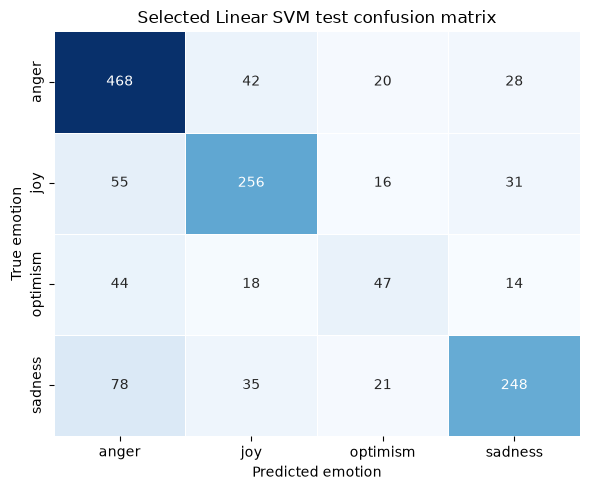

In [30]:
final_training_tokens = train_tokens + val_tokens
final_training_labels = np.concatenate([y_train, y_val])
final_svm_pipeline = clone(selected_search_pipeline).set_params(**selected_svm_params)
final_svm_pipeline.fit(final_training_tokens, final_training_labels)

test_predictions = final_svm_pipeline.predict(test_tokens)
print("Selected model:", selected_model_name)
print("Final test metrics:")
print(classification_report(
    y_test, test_predictions, labels=list(emotion_labels),
    target_names=label_names, digits=3, zero_division=0,
))

confusion_values = confusion_matrix(
    y_test, test_predictions, labels=list(emotion_labels)
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    confusion_values, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=label_names, yticklabels=label_names, linewidths=0.5, ax=ax,
)
ax.set(title="Selected Linear SVM test confusion matrix", xlabel="Predicted emotion", ylabel="True emotion")
fig.tight_layout()
display(fig)
plt.close(fig)


### Review test errors

In [31]:
error_mask = test_predictions != y_test
error_table = test_df.loc[error_mask, ["text", "emotion"]].rename(
    columns={"text": "Tweet", "emotion": "True emotion"}
).copy()
error_table["Predicted emotion"] = [
    emotion_labels[int(label)] for label in test_predictions[error_mask]
]
print(f"Misclassified test tweets: {error_mask.sum()} / {len(test_df)}")
display(error_table.head(20))


Misclassified test tweets: 402 / 1421


,Tweet,True emotion,Predicted emotion
0,#Deppression is real. Partners w/ #depressed p...,sadness,anger
4,What makes you feel #joyful?,joy,sadness
8,@user @user #cmbyn does screen August 4 &amp;...,sadness,joy
15,@user #shocking loss of talented young man#pra...,sadness,anger
25,Favorite character who's name starts with the ...,joy,optimism
26,I'm so nervous I could puke + my body temp is ...,joy,sadness
30,@user Is it just me that thinks it looks boring?,sadness,optimism
36,"@user No #racism, no #hatred , no #sectarianis...",optimism,anger
37,sleep is and will always be one of the best re...,optimism,sadness
39,yukwon no video do zico the world is shaking,sadness,joy
